# A1: Vision Transformers em fotos aéreas de casas de Austin

Notebook fino: ele chama as mesmas classes do pacote `visaocomp` que o `make data`, o `make run-a1-scratch` e o `make run-a1-pretrained`. Toda a lógica está em `src/visaocomp/a1/` e `src/visaocomp/vit/`.

A tarefa: em cada recorte de foto aérea (NAIP, 0,6 m por pixel, 96 x 96 px, centrado numa casa), dizer se a casa tem **piscina** e se tem **painel solar**, ou "não dá para dizer", com o motivo. Os dados são todos públicos: lotes, endereços e licenças da cidade de Austin, prédios do Overture, piscinas do OpenStreetMap e fotos do NAIP pelo Planetary Computer.

**Requisitos**
- Memória: cerca de 4 GB de RAM; os recortes (cerca de 7.900, 96 x 96) cabem na GPU como uint8.
- Dispositivo: GPU do Colab (T4), Apple MPS ou CPU, escolhido automaticamente.
- Disco: cerca de 1 GB (recortes RGB e NIR, catálogo DuckDB e checkpoints).
- Tempo, medido no Apple M5 (MPS): dados da A1 (consultas públicas e recortes) de 10 a 20 min na primeira vez; ViT do zero, 28 min (75 épocas); ViT-S pré-treinado e ResNet-18, cerca de 20 min. Na T4 do Colab não foi medido.
- Rede: APIs públicas da cidade de Austin, Overpass (OSM), Overture (S3) e Planetary Computer; e os pesos do ImageNet (timm e torchvision). Nenhuma chave é necessária.
- Cada etapa só roda se o resultado ainda não existe em `outputs/`. Troque `FORCE_RUN` para `True` para refazer.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/lararli/ml-visao-computacional.git"  # o repositório da entrega; no Colab, esta célula clona e instala

if IN_COLAB and not Path("pyproject.toml").exists():
    assert REPO_URL, "preencha REPO_URL"
    !git clone {REPO_URL} repo
    %cd repo
    %pip install -q -e .

# sobe até a pasta que tem o pyproject.toml, para os caminhos relativos funcionarem
root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root / "src"))
root

PosixPath('.')

## 1. Dados (a mesma montagem do `make data`, idempotente)

Lote, endereço e casa; licenças; piscinas do OSM; recortes do NAIP; NDVI; rótulos; split por células de 1 km. Tudo vai para o `catalog.duckdb` (bronze, silver e gold).

In [2]:
import subprocess

import duckdb

from visaocomp.paths import data_dir

catalog = data_dir() / "catalog.duckdb"


def has_chips() -> bool:
    if not catalog.exists():
        return False
    con = duckdb.connect(str(catalog), read_only=True)
    try:
        return con.execute(
            "SELECT count(*) FROM information_schema.tables WHERE table_name = 'chip'"
        ).fetchone()[0] > 0
    finally:
        con.close()


if not has_chips():
    subprocess.run([sys.executable, "scripts/build_a1.py"], check=True)
con = duckdb.connect(str(catalog), read_only=True)
print(con.execute("SELECT split, count(*) AS recortes FROM silver.chip GROUP BY split ORDER BY split").df())
con.close()

   split  recortes
0   test      1135
1  train      5552
2    val      1197


## 2. ViT do zero (R06 a R09, R11, R12)

Atenção, multi-head, bloco do encoder e ViT escritos à mão em `src/visaocomp/vit/`; treino multirrótulo com BCE e peso nos positivos.

In [3]:
from visaocomp.a1.scratch_cli import run_scratch
from visaocomp.a1.scratch_report import latest_run

FORCE_RUN = False
scratch_run = latest_run(root / "outputs")
if FORCE_RUN or scratch_run is None:
    run_scratch()
    scratch_run = latest_run(root / "outputs")

In [4]:
import json

import pandas as pd

scratch = json.loads((scratch_run / "a1_scratch" / "metrics.json").read_text(encoding="utf-8"))
print(f"run {scratch['run_id']}: {scratch['model']['params']:,} parâmetros, melhor época {scratch['train']['best_epoch']}")
pd.DataFrame(scratch["test"]["per_attribute"]).T[["n", "n_pos", "precision", "recall", "f1", "pr_auc", "prevalence"]]

run 20261012-233015-a1_scratch: 2,735,042 parâmetros, melhor época 37


,n,n_pos,precision,recall,f1,pr_auc,prevalence
pool,925,137,0.27027,0.583942,0.369515,0.355629,0.148108
solar,1086,82,0.319444,0.280488,0.298701,0.253078,0.075506


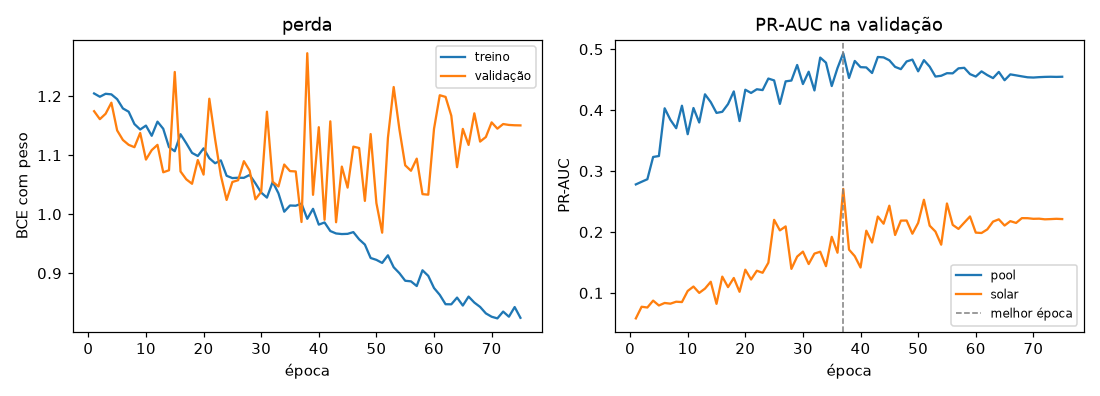

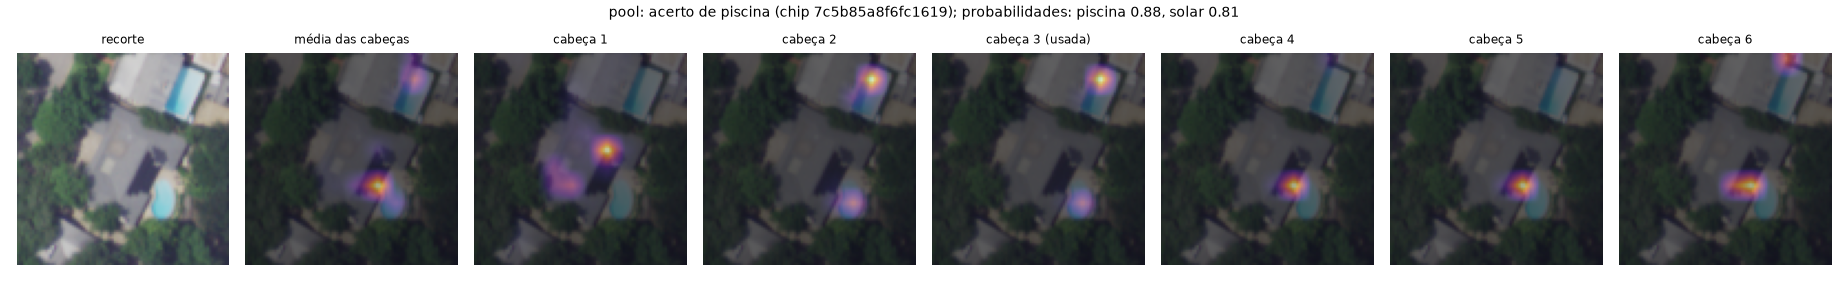

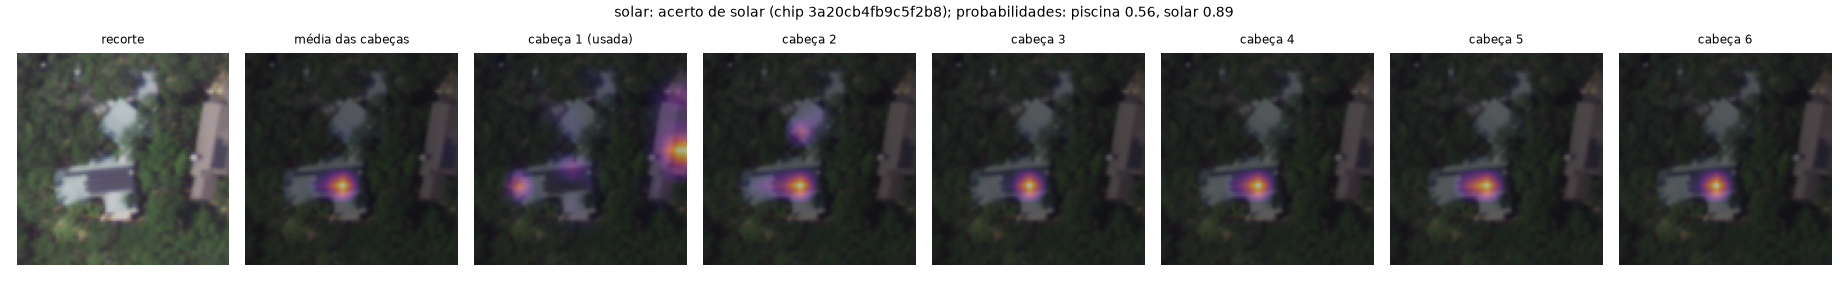

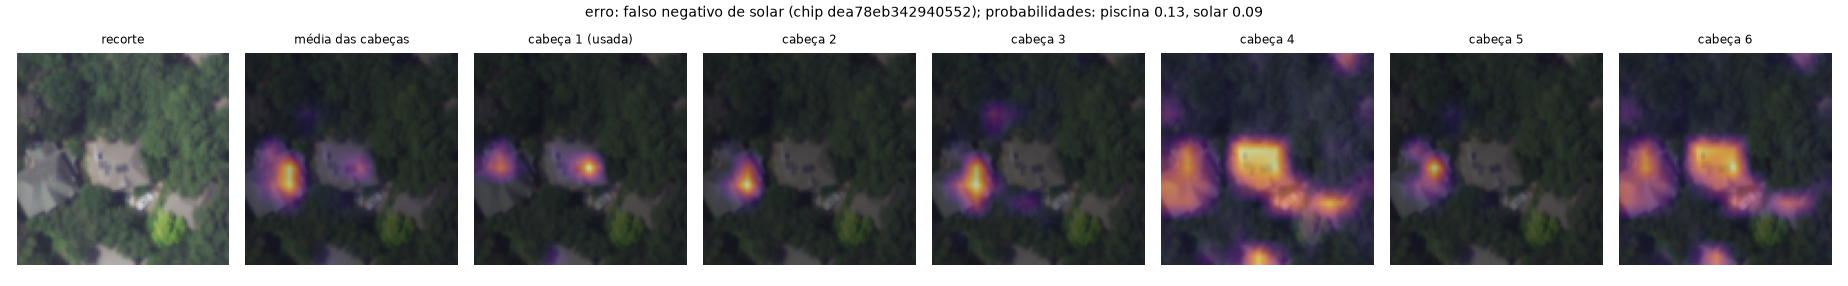

In [5]:
from IPython.display import Image, display

for name in ["curves.png", *scratch["attention"]["figures"]]:
    display(Image(filename=str(root / "reports" / "figures" / "a1" / name)))

## 3. ViT pré-treinado e ResNet-18, "não dá" com motivo e gold (R10, R13 a R16)

Mesmos recortes, split, perda e métricas. A regra de abstenção é escolhida na validação; a gold vai para o `catalog.duckdb` por MERGE.

In [6]:
from visaocomp.a1.pretrained_cli import latest
from visaocomp.a1.pretrained_cli import main as run_pretrained

FORCE_RUN = False
try:
    pre_run = latest(root / "outputs", "a1_pretrained")
except FileNotFoundError:
    pre_run = None
if FORCE_RUN or pre_run is None or not (pre_run / "a1_pretrained" / "comparison.csv").exists():
    run_pretrained([])
    pre_run = latest(root / "outputs", "a1_pretrained")
comp = pd.read_csv(pre_run / "a1_pretrained" / "comparison.csv")
comp.pivot_table(index=["attribute", "eval_set"], columns="model", values=["f1", "pr_auc"]).round(2)

f1                 \
model                                         resnet18 vit_pretrained   
attribute eval_set                                                      
pool      amostra conferida (marcação a olho)     0.69           0.80   
          teste inteiro (rótulo do catálogo)      0.41           0.40   
solar     amostra conferida (marcação a olho)     0.64           0.66   
          teste inteiro (rótulo do catálogo)      0.54           0.56   

                                                            pr_auc  \
model                                         vit_scratch resnet18   
attribute eval_set                                                   
pool      amostra conferida (marcação a olho)        0.81     0.85   
          teste inteiro (rótulo do catálogo)         0.37     0.35   
solar     amostra conferida (marcação a olho)        0.37     0.75   
          teste inteiro (rótulo do catálogo)         0.30     0.49   

                                                                          
model                                         vit_pretrained vit_scratch  
attribute eval_set                                                        
pool      amostra conferida (marcação a olho)           0.86        0.78  
          teste inteiro (rótulo do catálogo)            0.30        0.36  
solar     amostra conferida (marcação a olho)           0.88        0.36  
          teste inteiro (rótulo do catálogo)            0.60        0.25

In [7]:
abstain = json.loads((pre_run / "a1_pretrained" / "abstain.json").read_text(encoding="utf-8"))
print("modelo da gold:", abstain["model"])
pd.DataFrame({a: {**s["catalog"], "reasons": s["catalog"]["reasons"]} for a, s in abstain["test"].items()}).T

modelo da gold: vit_pretrained


,n,sim,não,não dá,coverage,reasons,yes_precision,no_npv,yes_n_truth,no_n_truth
pool,1135,166,567,402,0.645815,"{'incerto': 196, 'árvore': 206}",0.337349,0.936057,166,563
solar,1135,111,971,53,0.953304,"{'incerto': 4, 'árvore': 49}",0.477477,0.972194,111,971


In [8]:
con = duckdb.connect(str(catalog), read_only=True)
gold = con.execute("""
    SELECT a.parcel_id, a.address, a.attribute, a.decision, round(a.probability, 2) AS p, a.reason,
           e.agreement, a.model_version
    FROM gold.austin_house_attribute a
    JOIN gold.austin_house_attribute_evidence e USING (parcel_id, attribute)
    ORDER BY a.attribute, a.probability DESC
    LIMIT 12
""").df()
con.close()
gold

,parcel_id,address,attribute,decision,p,reason,agreement,model_version
0,0115150410,302 BUCKEYE TRL,pool,sim,0.91,NaN,imagem sem licença,vit_pretrained-b0e7f74e69da
1,0125050504,3901 BALCONES DR,pool,sim,0.88,NaN,concorda,vit_pretrained-b0e7f74e69da
2,0115130602,1111 WESTLAKE DR,pool,sim,0.87,NaN,imagem sem licença,vit_pretrained-b0e7f74e69da
3,0122060412,3407 TIMBERWOOD CIR,pool,sim,0.85,NaN,concorda,vit_pretrained-b0e7f74e69da
4,0115150415,402 BUCKEYE TRL,pool,não dá,0.85,árvore,não dá,vit_pretrained-b0e7f74e69da
5,0123130815,2312 TORO CANYON RD,pool,sim,0.84,NaN,imagem sem licença,vit_pretrained-b0e7f74e69da
6,0123130106,2100 N OAK CANYON RD,pool,sim,0.84,NaN,imagem sem licença,vit_pretrained-b0e7f74e69da
7,0117110502,4 HULL CIR,pool,sim,0.83,NaN,imagem sem licença,vit_pretrained-b0e7f74e69da
8,0115130609,1113 WESTLAKE DR,pool,sim,0.83,NaN,imagem sem licença,vit_pretrained-b0e7f74e69da
9,0115150213,602 W LEDGEWAY,pool,sim,0.82,NaN,imagem sem licença,vit_pretrained-b0e7f74e69da


## 4. Texto da análise, gerado dos mesmos arquivos de resultado

In [9]:
from IPython.display import Markdown

Markdown((root / "reports" / "sections" / "a1.md").read_text(encoding="utf-8").replace("../figures/", "reports/figures/"))

# A1: Vision Transformer em casas de Austin

<!-- a1_scratch:inicio -->
## ViT do zero

Gerado por `make run-a1-scratch` a partir de `outputs/20261012-233015-a1_scratch/a1_scratch/metrics.json`. Não
edite à mão: o texto de análise fica em `reports/a1_scratch_narrativa.yaml` e os números vêm do run.
A tarefa é multirrótulo: cada recorte de 96 x 96 px (cerca de 58 m de lado) tem duas saídas, piscina
e solar, cada uma um "sim ou não" independente.

### Arquitetura feita à mão (R06, R08, R11)

| Módulo | Arquivo | O que faz |
|---|---|---|
| `ScaledDotProductAttention` | `src/visaocomp/vit/attention.py` | softmax(Q K^T / raiz(d_k)) V; devolve a saída e os pesos |
| `AttentionHead` | `src/visaocomp/vit/attention.py` | uma cabeça com as suas próprias projeções Q, K e V |
| `MultiHeadAttention` | `src/visaocomp/vit/attention.py` | 6 cabeças independentes, concatenadas, e a projeção de saída W_O |
| `TransformerEncoderBlock` | `src/visaocomp/vit/encoder.py` | x + MHA(LayerNorm(x)); x + FFN(LayerNorm(x)); FFN = Linear, GELU, Linear |
| `PatchEmbedding` | `src/visaocomp/vit/model.py` | convolução 8 x 8 com stride 8: cada patch vira um vetor de 192 |
| `VisionTransformer` | `src/visaocomp/vit/model.py` | CLS aprendível + posição aprendível + 6 blocos + LayerNorm + cabeça de 2 logits |

Imagem 96 x 96 com patch 8: 12 x 12 patches, mais o CLS, dá 145 tokens de dimensão 192.
São 2.735.042 parâmetros, todos treinados do zero (nenhum peso pré-treinado).

### Positional encoding (R09)

A atenção compara cada token com todos os outros por produto escalar (Q K^T) e soma os V com esses
pesos. Nada nessa conta depende da ordem dos tokens. Se a fila de patches for embaralhada, cada
token encontra os mesmos vizinhos, com os mesmos pesos, só que em outro lugar da fila. Sem
positional encoding, o encoder é equivariante à permutação: embaralhar a entrada só embaralha as
saídas. O CLS olha para todos os patches com pesos que não dependem da ordem, então o logit dele
não muda. Numa foto aérea isso é ruim: o modelo não saberia se a mancha azul está no quintal da
casa do centro ou na borda, no lote do vizinho, nem se a mancha escura está sobre o telhado.

Por isso o ViT soma a cada token um vetor de posição aprendido (`pos_embed`, um por lugar da grade
de patches, mais um para o CLS). É a posição aprendida do ViT original, e não a fórmula de seno e
cosseno do Transformer de 2017 (aula 02, seção 2.7; aula 04, seção 2.7). Com ela, o mesmo patch
em lugares diferentes vira tokens diferentes.

Medido no modelo treinado, com 64 recortes do teste e os patches embaralhados na mesma
ordem aleatória: com a posição, a probabilidade muda em média 0.061 (no máximo
0.393). Com a posição zerada, o maior desvio do logit é 5.4e-07, que é só
arredondamento do float32. O teste `test_permutacao_sem_posicao_so_embaralha_com_posicao_muda`
(`tests/test_vit_modules.py`) prova o mesmo num ViT pequeno: sem posição, os tokens de saída saem
na ordem permutada e o logit fica igual; com posição, o logit muda.

### Treino do zero (R12)

| Item | Valor |
|---|---|
| Split | o da montagem dos dados (células de 1 km): treino 5552, validação 1197, teste 1135 |
| Perda | BCE por atributo, rótulo vazio fora, peso nos positivos piscina 3.6, solar 14.2 |
| Otimizador | AdamW, lr 0.0005, weight decay 0.05, 5 épocas de aquecimento e cosseno |
| Lote e épocas | 128 e 75 |
| Augmentation | giros de 90 graus, espelho e brilho leve (foto aérea não tem "cima") |
| Melhor época (PR-AUC médio na validação) | 37 (0.382) |
| Limiar por atributo (máximo F1 na validação) | piscina 0.57, solar 0.80 |
| Dispositivo e tempo de treino | mps, 28 min |

![curvas](reports/figures/a1/curves.png)

### Resultados no teste

O teste é usado uma vez. A "amostra conferida" são os 200 recortes do teste que foram
marcados a olho (`conferencia_inicial.csv`, copiado para `silver.label.first_check`): "sim" = 1, "não" = 0, e
"não dá" fica fora. A última coluna é o PR-AUC de um palpite ao acaso, que é igual à fração de
positivos: é o baseline.

| Atributo | Conjunto (verdade) | n | Positivos | Precision | Recall | F1 | PR-AUC | PR-AUC do acaso |
|---|---|---|---|---|---|---|---|---|
| piscina | teste inteiro (rótulo do catálogo) | 925 | 137 | 0.27 | 0.58 | 0.37 | 0.36 | 0.15 |
| piscina | amostra conferida (marcação a olho) | 165 | 67 | 0.75 | 0.87 | 0.81 | 0.78 | 0.41 |
| piscina | amostra conferida (rótulo do catálogo) | 173 | 60 | 0.46 | 0.62 | 0.52 | 0.55 | 0.35 |
| solar | teste inteiro (rótulo do catálogo) | 1086 | 82 | 0.32 | 0.28 | 0.30 | 0.25 | 0.08 |
| solar | amostra conferida (marcação a olho) | 175 | 21 | 0.36 | 0.38 | 0.37 | 0.36 | 0.12 |
| solar | amostra conferida (rótulo do catálogo) | 194 | 53 | 0.60 | 0.28 | 0.38 | 0.50 | 0.27 |

Contra o rótulo automático do catálogo, no teste inteiro, os dois atributos ficam acima do acaso,
mas longe de bons: piscina com F1 0.37 e PR-AUC 0.36 (acaso
0.15); solar com F1 0.30 e PR-AUC 0.25 (acaso
0.08).

A amostra conferida mostra que boa parte do "erro" da piscina é erro do rótulo, e não do modelo.
A comparação justa usa os mesmos recortes com as duas verdades: contra o catálogo, a piscina tem
precision 0.46 e F1 0.52; contra a marcação a olho, precision
0.75, recall 0.87 e F1 0.81. O OSM e as licenças não
têm todas as piscinas de Austin: o modelo acha piscinas que o catálogo marca como "não", e o teste
automático conta isso como falso positivo. A amostra tem mais positivos que o teste (fração de
positivos 0.41 contra 0.15), então os números dela não
substituem os do teste inteiro; eles medem o ruído do rótulo.

O solar é o ponto fraco. Na amostra conferida, o F1 é 0.37 (precision
0.36, recall 0.38), igual ao do catálogo nos mesmos recortes
(0.38). Os dois rótulos discordam muito: o catálogo tem 53
positivos nesses recortes e a marcação a olho, 21. Uma licença de solar não
garante um painel visível na foto (o painel pode estar sob árvores, na face do telhado que a foto
não mostra bem, ou ainda não estar instalado). E o objeto é pequeno: a 0,6 m por pixel, um
conjunto de painéis cabe em um ou dois patches de 8 x 8. Os falsos positivos vêm de partes escuras
do telhado, como sombra de árvore e claraboia.

Para o negócio: a piscina do zero já separa bem os casos quando a verdade é boa, e serve como
filtro com conferência humana. O solar ainda não serve para decidir nada sozinho. A parte pré-treinada (abaixo) compara
com um ViT pré-treinado e com uma CNN, que precisam de menos dados para aprender formas pequenas.

### Mapas de atenção (R07, R12)

Cada mapa é a linha do token CLS na última camada: quanto o CLS, que decide a classe, olha para cada
um dos 12 x 12 patches. O mapa é ampliado para 96 x 96 e posto sobre o recorte. A figura mostra a média das 6 cabeças e
cada cabeça; a marcada "(usada)" é a que mais olha para a região do atributo (piscina: cabeça
3; solar: cabeça 1).

![attention_pool.png](reports/figures/a1/attention_pool.png)

![attention_solar.png](reports/figures/a1/attention_solar.png)

![attention_erro.png](reports/figures/a1/attention_erro.png)

Para não depender só de três exemplos, a tabela mede, em todo o teste, quanto da atenção do CLS cai
no telhado (o contorno da casa na montagem dos dados) e na piscina (os polígonos do OSM dentro do recorte),
dividido pela área que a região ocupa. Razão 1 é o acaso; 2 quer dizer que a região recebe o dobro
da atenção que a área dela explicaria.

| Região | Recortes | Atenção do CLS na região | Área da região | Razão (média das cabeças) | Razão por cabeça (1 a 6) |
|---|---|---|---|---|---|
| telhado da casa, todo o teste | 1135 | 30% | 11% | 3.0 | 4.3 / 3.3 / 2.9 / 2.2 / 3.5 / 2.0 |
| telhado, recortes que o modelo diz solar | 72 | 53% | 14% | 4.5 | 4.2 / 3.7 / 3.7 / 5.1 / 5.5 / 4.9 |
| piscina do OSM no recorte, todo o teste | 95 | 27% | 1% | 18.7 | 2.6 / 32.8 / 35.8 / 9.8 / 27.8 / 3.4 |
| piscina do OSM, recortes que o modelo diz piscina | 56 | 35% | 2% | 23.5 | 3.1 / 40.4 / 43.9 / 14.7 / 33.8 / 4.8 |

O modelo olha para o lugar certo. Em todo o teste, o telhado ocupa 11% do recorte e
recebe 30% da atenção do CLS (razão 3.0). Nos recortes em que o modelo
diz "solar", a razão sobe para 4.5 (53% da atenção no
telhado): para decidir solar, ele olha para o telhado.

Na piscina, as cabeças se especializam, que é a ideia da atenção com várias cabeças (aula 04): os
polígonos de piscina ocupam só 1% do recorte e recebem 27% da
atenção. As cabeças 2, 3 e 5 dão à piscina várias dezenas de vezes a atenção que a área explicaria
(a maior chega a 35.8). As cabeças 1 e 6 ficam perto de 3: elas olham para
outras coisas, como o telhado e as sombras. Nos recortes em que o modelo diz "piscina", a média das
cabeças sobe de 18.7 para 23.5.

Os três exemplos mostram o mesmo e mostram os limites. No acerto de piscina
(7c5b85a8f6fc1619, probabilidade 0.88), há duas piscinas no recorte: as cabeças 2
e 3 acendem as duas, inclusive a do lote vizinho no alto, e as cabeças 4 a 6 olham para a sombra
escura ao lado da piscina de baixo. O mesmo recorte recebe solar 0.81, mas a
marcação a olho diz "não": a cabeça 1 está numa mancha escura do telhado, e esse é o padrão do
falso positivo de solar. No acerto de solar (3a20cb4fb9c5f2b8, probabilidade
0.89), as cabeças 2 a 6 se juntam no retângulo escuro do telhado, que são os
painéis. No erro (dea78eb342940552, solar 0.09), as cabeças 1, 2, 3 e 5 olham
para o telhado do vizinho, na borda esquerda, e não para a casa do centro; as cabeças 4 e 6 se
espalham pelo telhado e pelas árvores. O modelo olhou para a casa errada.

### Limites

- Rótulo com ruído. O treino usa o rótulo automático (polígonos do OSM e licenças de solar). Ele
  perde piscinas e confunde "tem licença" com "painel visível". A amostra conferida tem só
  200 recortes, escolhidos com mais positivos, e teve uma conferência inicial; a conferência
  da Lara (`lara.csv`) ainda não entrou nestes números.
- O recorte tem vizinhos. Ele tem cerca de 58 m de lado, centrado na casa, e pega o lote ao lado.
  Uma piscina do vizinho conta como piscina da casa (exemplo de acerto acima). Cortar pelo
  polígono do lote resolveria isso; ficou fora da POC.
- Foto e licença de datas diferentes. A foto do NAIP é de um ano só; uma licença não garante que o
  painel estava instalado e visível naquela foto.
- Um treino, uma seed. O treino no MPS (GPU do Mac) não é idêntico bit a bit entre execuções, e
  não há intervalo de confiança. Diferenças pequenas contra os pré-treinados não provam nada.
- ViT do zero com poucos dados. O ViT não tem o viés de localidade da convolução e precisa de muitos
  dados para aprender o que uma CNN já assume (aula 04). Os 2.735.042 parâmetros aprenderam com
  poucos milhares de recortes; é por isso que a parte pré-treinada usa pesos pré-treinados.
<!-- a1_scratch:fim -->

<!-- a1_pretrained:inicio -->
## ViT pré-treinado, CNN e a decisão com motivo

Gerado por `make run-a1-pretrained` a partir de `outputs/20261013-001531-a1_pretrained/a1_pretrained/`. Não edite à
mão: o texto de análise fica em `reports/a1_pretrained_narrativa.yaml` e os números vêm do run.
Mesmos recortes, mesmo split (células de 1 km), mesma perda, mesma augmentation e mesmas métricas do
ViT do zero. Muda só o modelo e o treino curto.

### Fine-tuning do ViT pré-treinado (R13)

| Item | ViT-S/16 pré-treinado | ResNet-18 pré-treinada |
|---|---|---|
| Pesos | timm `vit_small_patch16_224` (ImageNet-21k, ajustado no 1k) | torchvision `IMAGENET1K_V1` |
| Cabeça | trocada: `head` = Linear(384, 2) | trocada: `fc` = Linear(512, 2) |
| Entrada | recorte 96 x 96 ampliado para 224 x 224 e normalizado com a média do ImageNet, dentro do modelo | igual |
| Treino | 6 épocas, lr 5e-05, corpo inteiro ajustado | 6 épocas, lr 0.0003 |
| Versão gravada | `vit_pretrained-b0e7f74e69da` | `resnet18-8372f946d8a2` |

O fine-tuning troca só a última camada: a cabeça do ImageNet (1.000 classes) sai e entra uma
Linear de 384 para 2 (piscina e solar), com pesos novos. O corpo inteiro
continua treinável, mas com lr 5e-05, dez vezes menor que o do ViT do zero: o
corpo já sabe ver bordas, cantos e texturas, e um passo grande apagaria isso. Por isso bastam
6 épocas, contra 75 do zero.

O recorte de 96 x 96 é ampliado para 224 x 224, que é o tamanho em que o modelo foi pré-treinado.
Cada patch de 16 x 16 da entrada ampliada cobre cerca de 7 x 7 pixels do recorte (uns 4 m no
chão). A ampliação não cria detalhe novo; ela só põe a imagem na escala que o corpo conhece.

Na validação, o PR-AUC médio (piscina e solar) vai de 0.382 no ViT do zero
para 0.598 no pré-treinado, com 14 min de treino
contra 28 min.

### Tabela comparativa (R13, R16)

| Atributo | Conjunto (verdade) | Modelo | Precision | Recall | F1 | PR-AUC | Acaso | Parâmetros | Treino (min) |
|---|---|---|---|---|---|---|---|---|---|
| piscina | teste inteiro (rótulo do catálogo) | ViT do zero | 0.27 | 0.58 | 0.37 | 0.36 | 0.15 | 2.7 M | 28 |
| piscina | amostra conferida (marcação a olho) | ViT do zero | 0.75 | 0.87 | 0.81 | 0.78 | 0.41 | 2.7 M | 28 |
| solar | teste inteiro (rótulo do catálogo) | ViT do zero | 0.32 | 0.28 | 0.30 | 0.25 | 0.08 | 2.7 M | 28 |
| solar | amostra conferida (marcação a olho) | ViT do zero | 0.36 | 0.38 | 0.37 | 0.36 | 0.12 | 2.7 M | 28 |
| piscina | teste inteiro (rótulo do catálogo) | ViT-S/16 pré-treinado (timm vit_small_patch16_224) | 0.29 | 0.66 | 0.40 | 0.30 | 0.15 | 21.7 M | 14 |
| piscina | amostra conferida (marcação a olho) | ViT-S/16 pré-treinado (timm vit_small_patch16_224) | 0.82 | 0.79 | 0.80 | 0.86 | 0.41 | 21.7 M | 14 |
| solar | teste inteiro (rótulo do catálogo) | ViT-S/16 pré-treinado (timm vit_small_patch16_224) | 0.48 | 0.67 | 0.56 | 0.60 | 0.08 | 21.7 M | 14 |
| solar | amostra conferida (marcação a olho) | ViT-S/16 pré-treinado (timm vit_small_patch16_224) | 0.50 | 0.95 | 0.66 | 0.88 | 0.12 | 21.7 M | 14 |
| piscina | teste inteiro (rótulo do catálogo) | ResNet-18 pré-treinada (torchvision) | 0.32 | 0.57 | 0.41 | 0.35 | 0.15 | 11.2 M | 5 |
| piscina | amostra conferida (marcação a olho) | ResNet-18 pré-treinada (torchvision) | 0.76 | 0.63 | 0.69 | 0.85 | 0.41 | 11.2 M | 5 |
| solar | teste inteiro (rótulo do catálogo) | ResNet-18 pré-treinada (torchvision) | 0.45 | 0.67 | 0.54 | 0.49 | 0.08 | 11.2 M | 5 |
| solar | amostra conferida (marcação a olho) | ResNet-18 pré-treinada (torchvision) | 0.51 | 0.86 | 0.64 | 0.75 | 0.12 | 11.2 M | 5 |

**Escolha: o ViT-S pré-treinado.** Ele tem o maior PR-AUC médio na validação
(0.598, contra 0.554 da ResNet-18 e
0.382 do ViT do zero). A escolha usa a validação, e não o teste, para o teste
continuar sendo uma medida limpa. É o modelo que alimenta a gold.

O maior ganho é no solar, o atributo pequeno. No teste inteiro, o PR-AUC vai de
0.25 (do zero) para 0.60
(pré-treinado). Na amostra conferida a olho, o F1 vai de 0.37 para
0.66, com recall 0.95. O corpo
pré-treinado já sabe ver bordas finas, retângulos e texturas, e é isso que um painel de um ou dois
patches precisa.

Na piscina, o rótulo automático esconde a diferença. Contra ele, os três ficam baixos e perto um do
outro (PR-AUC 0.36, 0.30 e
0.35), e o pré-treinado parece até pior que o do zero. Contra a marcação a
olho, a ordem se inverte: PR-AUC 0.86 no pré-treinado,
0.85 na ResNet-18 e 0.78 no do zero. O
pré-treinado acha piscinas que o OSM e as licenças não têm, e o teste automático conta cada uma como
erro. Por isso a amostra conferida pesa na escolha.

A ResNet-18 chega perto: no solar, F1 0.54 contra
0.56 no teste inteiro, com metade dos parâmetros
(11.2 M contra 21.7 M) e 5 min de
treino contra 14. Ela é a alternativa barata se o custo de rodar na cidade
inteira pesar mais que alguns centésimos de PR-AUC. O ViT do zero fica como linha de base e como
ferramenta para entender a atenção.

Cuidado com diferenças pequenas: cada modelo treinou uma vez, numa seed, e a amostra conferida tem
menos de 200 recortes por atributo. Uma diferença de poucos centésimos entre o ViT-S e a ResNet-18
não prova que um é melhor; a diferença contra o ViT do zero, sim.

### Sim, não ou "não dá para dizer"

A regra roda no modelo escolhido (ViT-S/16 pré-treinado (timm vit_small_patch16_224)). A ordem dos motivos é fixa: sem prédio, árvore
(NDVI do telhado para solar e do quintal para piscina, os mesmos limites da montagem dos dados), não visível de
cima (cerca, revestimento, janela e porta, que a POC cortou), e incerto. A faixa de incerteza é
escolhida na validação: abaixo dela o "não" acerta pelo menos 95%, acima dela o "sim" acerta pelo
menos 60%, sempre contra o rótulo do catálogo.

| Atributo | Faixa de incerteza (p) | sim | não | não dá | Motivos | Cobertura | Acerto do sim (catálogo / conferida) | Acerto do não (catálogo / conferida) |
|---|---|---|---|---|---|---|---|---|
| piscina | 0.36 a 0.58 | 166 | 567 | 402 | incerto 196, árvore 206 | 65% | 0.34 / 0.88 | 0.94 / 0.89 |
| solar | 0.70 a 0.72 | 111 | 971 | 53 | incerto 4, árvore 49 | 95% | 0.48 / 0.51 | 0.97 / 0.99 |

Na piscina, o modelo decide em 65% das casas do teste: 166 "sim",
567 "não" e 402 "não dá" (206 por árvore e
196 por incerteza). Na amostra conferida, quando ele diz "sim", acerta
0.88; contra o catálogo, só 0.34,
pela mesma razão de antes: o catálogo não tem todas as piscinas. O "não" acerta
0.89 na amostra conferida.

No solar, ele decide em 95% das casas. A faixa de incerteza é estreita
(0.70 a 0.72), porque na validação o "sim" já acerta 60% logo acima do
limiar; quase todo "não dá" é árvore sobre o telhado (49 casas). Na
amostra conferida, o "sim" acerta 0.51 e o "não",
0.99.

A tabela de evidência é onde a POC vira trabalho. Na piscina, 110
casas têm piscina na foto e nenhuma licença nem registro no OSM: é a lista para conferir (obra sem
licença, ou cliente em potencial para manutenção). Outras 36 têm
registro e a foto diz "não": piscina coberta, obra não terminada ou erro do modelo. O "não dá" com
motivo diz quais casas precisam de outra fonte (foto de rua ou visita), em vez de um palpite.

### A camada gold

O resultado volta para o trabalho em duas tabelas do `catalog.duckdb`, gravadas por MERGE (rodar de
novo não duplica; um modelo novo grava linhas novas e não apaga as antigas):

- `gold.austin_house_attribute`: lote x atributo x ano da foto x versão do modelo, com endereço,
  coordenada, decisão, probabilidade, motivo, recorte e run. Nesta POC: 2270 linhas (as
  casas do teste).
- `gold.austin_house_attribute_evidence`: lote x atributo, cruza a decisão da imagem com a licença e o
  OpenStreetMap e grava `agreement` (concorda, imagem sem licença, licença sem imagem, não dá).

```sql
-- casas com piscina vista na foto e sem licença nem OSM: lista para o time comercial
SELECT a.parcel_id, a.address, a.probability
FROM gold.austin_house_attribute a
JOIN gold.austin_house_attribute_evidence e USING (parcel_id, attribute)
WHERE a.attribute = 'pool' AND a.model_version = e.model_version
  AND e.agreement = 'imagem sem licença'
ORDER BY a.probability DESC;
```

### BERT e ViT: o que cada pré-treino maximiza (R10)

Os dois aprendem sem rótulo humano, mas maximizam coisas diferentes.

O BERT (aula 03) é pré-treinado com o Masked Language Modeling: 15% dos tokens são escondidos e o
modelo precisa adivinhá-los pelo contexto dos dois lados. O original também tinha
o Next Sentence Prediction (a frase B vem depois da frase A?). O que ele maximiza é a probabilidade do token certo
dado o contexto: uma representação de cada palavra que depende da frase inteira. Texto é
discreto, então "adivinhe a palavra" é uma tarefa bem definida, e a internet dá dados à vontade.

O ViT original (aula 04) é pré-treinado de forma supervisionada: classificar imagens do
ImageNet-21k ou do JFT-300M. O que ele maximiza é acertar a classe da imagem inteira, pelo token
CLS. O pixel é contínuo e redundante, então esconder um patch é fácil de adivinhar pelos vizinhos
e ensina pouco; por isso o ViT de 2020 usou rótulos. As versões depois disso trouxeram a ideia do
BERT para a imagem: o MAE (Masked Autoencoder) esconde 75% dos patches e reconstrói os pixels, e
o DINO e o CLIP aprendem por comparação. O modelo pré-treinado usado aqui (`vit_small_patch16_224` do timm) é
do tipo supervisionado: ImageNet-21k e depois ImageNet-1k.

O que isso muda aqui: o pré-treino supervisionado do ViT ensinou formas e texturas de objetos do
dia a dia, fotografados de lado. Piscina e painel solar vistos de cima não estão no ImageNet. O
ganho vem das formas genéricas (bordas, cantos, contraste, cor), que servem em qualquer imagem;
e a cabeça nova aprende o resto com os nossos recortes.

### DeiT e Swin: o que resolvem que o ViT original não resolve (R14)

O ViT original tem três limites (aula 05): precisa de muitos dados (sem o viés de localidade da
convolução, ele só bate a ResNet com pré-treino em centenas de milhões de imagens); a atenção
global custa o quadrado do número de patches, então imagem grande ou patch pequeno fica caro; e
ele tem uma escala só (todos os patches do mesmo tamanho em todas as camadas), o que atrapalha
detecção e segmentação.

- DeiT (Data-efficient Image Transformer, Facebook, 2021) resolve a fome de dados. Treina só no
  ImageNet-1k (1,3 milhão de imagens) com augmentation forte e regularização, e com destilação:
  um token a mais, o token de destilação, aprende a imitar uma CNN professora. A CNN passa o viés
  de localidade para o ViT sem mudar a arquitetura. Para nós, é o caminho para treinar um ViT com
  poucas fotos aéreas, usando uma CNN treinada como professora.
- Swin Transformer (Microsoft, 2021) resolve o custo e a escala. A atenção é calculada dentro de
  janelas locais (custo linear no tamanho da imagem), e as janelas deslizam de uma camada para a
  outra para os patches de janelas vizinhas conversarem. Os patches são fundidos a cada estágio,
  como uma pirâmide de CNN, então o modelo vê objetos pequenos e grandes. Para nós, é o que
  permitiria olhar um lote inteiro em resolução alta e achar um painel pequeno no telhado.

Esta entrega não treina DeiT nem Swin; a escolha deles numa próxima versão está no
R15.

### Quando o ViT supera a CNN, e quando a CNN é melhor (R15)

**Quando o ViT supera a CNN.** Quando há pré-treino em muitos dados: com o ImageNet-21k, o ViT-S
passou a ResNet-18 na validação (0.598 contra 0.554). E
quando a decisão depende de partes distantes da imagem: a atenção liga, já na primeira camada,
qualquer patch a qualquer outro (a piscina ao fundo do lote e o telhado da casa), enquanto a CNN
precisa empilhar camadas para o campo receptivo crescer. Com mais dados, o ViT continua melhorando,
e a CNN satura antes (aula 04).

**Quando a CNN é melhor.** Com poucos dados e sem pré-treino: a convolução já assume localidade e
que um objeto é o mesmo em qualquer lugar da imagem, e o ViT precisa aprender isso com dados. O ViT
do zero, com cerca de 5.500 recortes, ficou em 0.382 na validação. Com pouco
computador ou pouco tempo de resposta: a ResNet-18 treinou em 5 min, com
11.2 M de parâmetros. Com imagem grande ou em resolução alta: a atenção custa o
quadrado do número de patches, e a convolução cresce linear (o Swin resolve isso com janelas).

**No nosso domínio.** Foto aérea de 0,6 m por pixel, recortes de 96 x 96, poucos milhares de
rótulos com ruído e objetos pequenos. O pré-treino é obrigatório; sem ele, nenhum dos dois serve:
no solar, o PR-AUC do teste é 0.25 no ViT do zero, contra
0.49 na ResNet-18 e 0.60 no ViT-S pré-treinado.
Entre os pré-treinados, a diferença é pequena. Para a POC e para a gold, o ViT-S, que acerta mais.
Para rodar a cidade inteira (centenas de milhares de lotes), a ResNet-18 é a opção de custo, e o
próximo teste seria um Swin em resolução maior, que junta a atenção com o custo da CNN.
<!-- a1_pretrained:fim -->

<!-- a1_lara:inicio -->
## Conferência da Lara

A Lara conferiu os 200 recortes da amostra, um a um, depois da conferência inicial (arquivo `lara.csv`). Em alguns casos ela usou uma imagem de maior resolução para decidir. A tabela mostra onde ela concorda com a conferência inicial e com o rótulo automático, e as métricas dos modelos pré-treinados contra a resposta dela (sim = 1, não = 0; "não dá" fica fora).

| Atributo | Sim / não / não dá (Lara) | Concorda com a conferência inicial | Rótulo automático igual ao da Lara |
|---|---|---|---|
| piscina | 96 / 93 / 11 | 76% | 71% (de 168 com rótulo) |
| solar | 44 / 149 / 6 | 82% | 94% (de 192 com rótulo) |

| Atributo | Modelo | n | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|---|---|
| piscina | ViT-S/16 pré-treinado (timm vit_small_patch16_224) | 189 | 0.90 | 0.72 | 0.80 | 0.91 |
| piscina | ResNet-18 pré-treinada (torchvision) | 189 | 0.85 | 0.53 | 0.65 | 0.87 |
| solar | ViT-S/16 pré-treinado (timm vit_small_patch16_224) | 193 | 0.81 | 0.86 | 0.84 | 0.92 |
| solar | ResNet-18 pré-treinada (torchvision) | 193 | 0.81 | 0.77 | 0.79 | 0.87 |

A Lara marcou mais piscinas que a conferência inicial: muitas aparecem na foto de maior resolução ou ficam no lote, mas fora do recorte de 58 m. Isso reforça dois limites já descritos: o recorte pega o lote vizinho e corta parte do próprio lote, e a foto de 0,6 m por pixel esconde piscinas pequenas ou sob árvores.
<!-- a1_lara:fim -->
